In [1]:
import os
import time
import collections
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchmetrics.classification import MulticlassAccuracy

from src.utils import (
    set_seed,
    get_device,
    get_fashion_mnist_loaders,
    evaluate_reconstruction,
    evaluate_fid,
    measure_latency_ms,
)
from src.models import (
    MLPClassifier,
    FrozenLatentDecoder,
    VanillaAutoencoder,
    SparseAutoencoder,
    sparse_ae_loss,
    VAE,
    vae_loss,
    VanillaGenerator,
    VanillaDiscriminator,
    DCGANGenerator,
    DCGANDiscriminator,
    DDPM,
)

SEED = 42
set_seed(SEED)
dev = get_device()
print(f"Using device: {dev}")
if dev.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")


os.makedirs("checkpoints", exist_ok=True)
os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)

# 2. Load Fashion-MNIST terstandarisasi (80% Train, 10% Val, 10% Test, batch_size=128)
BATCH_SIZE = 128
tr_dl, va_dl, te_dl = get_fashion_mnist_loaders(data_dir="data", batch_size=BATCH_SIZE, seed=SEED)

FASHION_LABELS = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]


Using device: cuda
GPU: NVIDIA GeForce RTX 2050


In [2]:
x_sample, y_sample = next(iter(tr_dl))
print(f"Batch shape : {x_sample.shape} | min={x_sample.min().item():.2f}, max={x_sample.max().item():.2f}")
print(f"Ada NaN?    : {torch.isnan(x_sample).any().item()}")
print(f"Split sizes : Train={len(tr_dl.dataset)}, Val={len(va_dl.dataset)}, Test={len(te_dl.dataset)}")

cnt = collections.Counter(int(lbl) for _, lbl in te_dl.dataset)
print("Distribusi kelas Test Set:", sorted(cnt.items()))


Batch shape : torch.Size([128, 1, 28, 28]) | min=0.00, max=1.00
Ada NaN?    : False
Split sizes : Train=56000, Val=7000, Test=7000
Distribusi kelas Test Set: [(0, 700), (1, 659), (2, 708), (3, 714), (4, 707), (5, 660), (6, 685), (7, 706), (8, 738), (9, 723)]


In [3]:
set_seed(SEED)
mlp_clf = MLPClassifier(latent_dim=64, num_classes=10).to(dev)
opt_mlp = torch.optim.Adam(mlp_clf.parameters(), lr=1e-3)
crit_mlp = nn.CrossEntropyLoss()
acc_metric = MulticlassAccuracy(num_classes=10).to(dev)

EPOCHS_MLP = 15
for epoch in range(EPOCHS_MLP):
    mlp_clf.train()
    running_loss = 0.0
    for x, y in tr_dl:
        x, y = x.to(dev), y.to(dev)
        opt_mlp.zero_grad()
        loss = crit_mlp(mlp_clf(x), y)
        loss.backward()
        opt_mlp.step()
        running_loss += loss.item() * x.size(0)
    avg_loss = running_loss / len(tr_dl.dataset)
    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f"[MLP Epoch {epoch+1:02d}/{EPOCHS_MLP}] Train Loss: {avg_loss:.4f}")

mlp_clf.eval()
with torch.no_grad():
    acc_metric.reset()
    for x, y in va_dl:
        acc_metric.update(mlp_clf(x.to(dev)), y.to(dev))
    val_acc = acc_metric.compute().item()

    acc_metric.reset()
    for x, y in te_dl:
        acc_metric.update(mlp_clf(x.to(dev)), y.to(dev))
    test_acc = acc_metric.compute().item()

print(f"MLP Validation Accuracy : {val_acc * 100:.2f}%")
print(f"MLP Test Accuracy       : {test_acc * 100:.2f}% (target >= 88%)")
assert test_acc >= 0.88, f"Test accuracy ({test_acc*100:.2f}%) belum mencapai 88%!"

torch.save(mlp_clf.state_dict(), "checkpoints/mlp_classifier.pt")
w1, w2, w3 = mlp_clf.fc1.weight.detach(), mlp_clf.fc2.weight.detach(), mlp_clf.fc3.weight.detach()
print("Weight shapes:", w1.shape, w2.shape, w3.shape)


[MLP Epoch 01/15] Train Loss: 0.6084
[MLP Epoch 05/15] Train Loss: 0.3147
[MLP Epoch 10/15] Train Loss: 0.2547
[MLP Epoch 15/15] Train Loss: 0.2126
MLP Validation Accuracy : 89.37%
MLP Test Accuracy       : 88.64% (target >= 88%)
Weight shapes: torch.Size([256, 784]) torch.Size([64, 256]) torch.Size([10, 64])


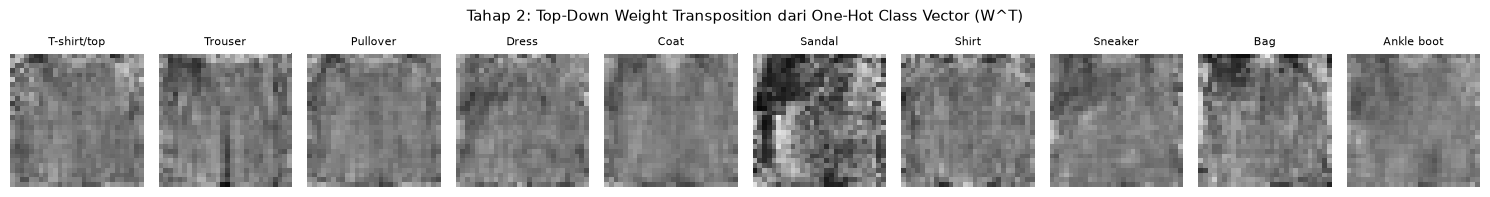

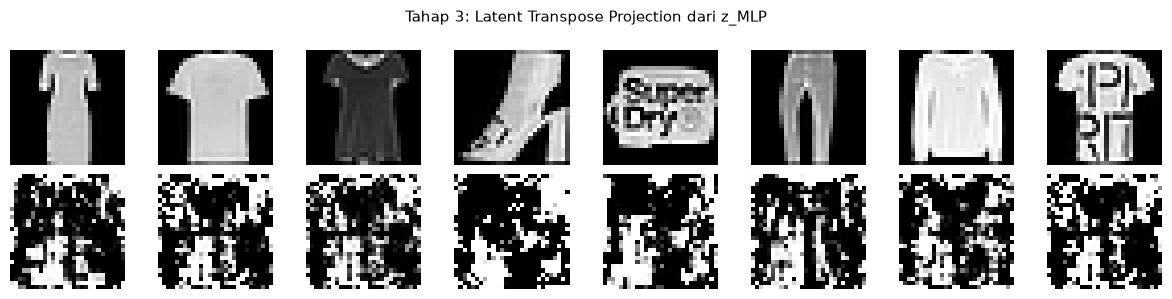

In [4]:

@torch.no_grad()
def topdown_from_class():
    y_onehot = torch.eye(10, device=dev)          # [10, 10]
    z_hat = F.relu(y_onehot @ w3)                 # W3^T y_c  (karena w3 berbentuk [10, 64])
    h1_hat = F.relu(z_hat @ w2)                   # W2^T z_hat
    x_hat = torch.sigmoid(h1_hat @ w1)            # Sigmoid(W1^T h1_hat)
    return x_hat.view(-1, 1, 28, 28)


@torch.no_grad()
def project_from_latent(x):
    z_mlp = mlp_clf.features(x.to(dev))
    h1_hat = F.relu(z_mlp @ w2)                   # ReLU(W2^T z_MLP)
    x_hat = torch.sigmoid(h1_hat @ w1)            # Sigmoid(W1^T h1_hat)
    return x_hat.view(-1, 1, 28, 28)


td_imgs = topdown_from_class().cpu()
fig, axes = plt.subplots(1, 10, figsize=(15, 2))
for i in range(10):
    axes[i].imshow(td_imgs[i, 0], cmap="gray", vmin=0, vmax=1)
    axes[i].set_title(FASHION_LABELS[i], fontsize=8)
    axes[i].axis("off")
plt.suptitle("Tahap 2: Top-Down Weight Transposition dari One-Hot Class Vector (W^T)", fontsize=11)
plt.tight_layout()
plt.show()


x_te_batch, _ = next(iter(te_dl))
x_te8 = x_te_batch[:8]
xh_latent8 = project_from_latent(x_te8).cpu()

fig, axes = plt.subplots(2, 8, figsize=(12, 3))
for i in range(8):
    axes[0, i].imshow(x_te8[i, 0], cmap="gray", vmin=0, vmax=1); axes[0, i].axis("off")
    axes[1, i].imshow(xh_latent8[i, 0], cmap="gray", vmin=0, vmax=1); axes[1, i].axis("off")
axes[0, 0].set_ylabel("Asli", fontsize=9)
axes[1, 0].set_ylabel("W^T(z_MLP)", fontsize=9)
plt.suptitle("Tahap 3: Latent Transpose Projection dari z_MLP", fontsize=11)
plt.tight_layout()
plt.show()


[Frozen Decoder Epoch 01/15] Train MSE: 0.03696
[Frozen Decoder Epoch 05/15] Train MSE: 0.02080
[Frozen Decoder Epoch 10/15] Train MSE: 0.01889
[Frozen Decoder Epoch 15/15] Train MSE: 0.01803
Frozen Latent Decoder (z_MLP) Test -> MSE: 0.01850 | PSNR: 17.33 dB | SSIM: 0.6968


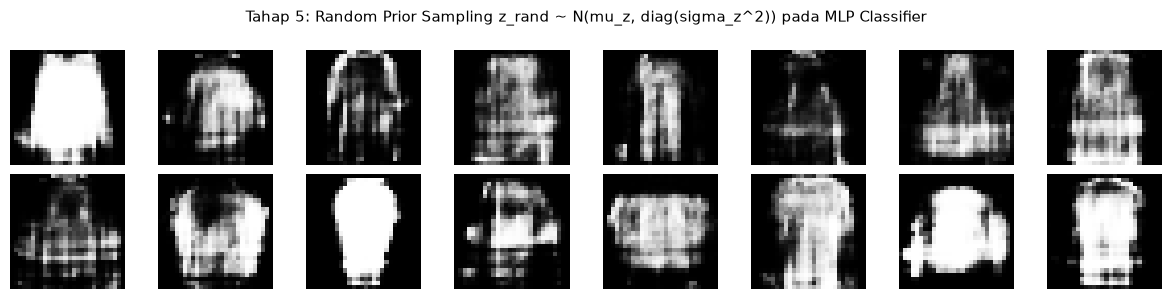

In [5]:

for p in mlp_clf.parameters():
    p.requires_grad = False
mlp_clf.eval()

set_seed(SEED)
frozen_dec = FrozenLatentDecoder(latent_dim=64).to(dev)
opt_dec = torch.optim.Adam(frozen_dec.parameters(), lr=1e-3)

EPOCHS_DEC = 15
for epoch in range(EPOCHS_DEC):
    frozen_dec.train()
    running_loss = 0.0
    for x, _ in tr_dl:
        x = x.to(dev)
        with torch.no_grad():
            z_mlp = mlp_clf.features(x)
        x_hat = frozen_dec(z_mlp)
        loss = F.mse_loss(x_hat, x)
        opt_dec.zero_grad()
        loss.backward()
        opt_dec.step()
        running_loss += loss.item() * x.size(0)
    avg_loss = running_loss / len(tr_dl.dataset)
    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f"[Frozen Decoder Epoch {epoch+1:02d}/{EPOCHS_DEC}] Train MSE: {avg_loss:.5f}")

torch.save(frozen_dec.state_dict(), "checkpoints/mlp_frozen_decoder.pt")

frozen_dec.eval()
mlp_dec_mse, mlp_dec_psnr, mlp_dec_ssim = evaluate_reconstruction(
    lambda x: frozen_dec(mlp_clf.features(x)), te_dl, dev
)
print(f"Frozen Latent Decoder (z_MLP) Test -> MSE: {mlp_dec_mse:.5f} | PSNR: {mlp_dec_psnr:.2f} dB | SSIM: {mlp_dec_ssim:.4f}")

with torch.no_grad():
    Z_mlp_test = torch.cat([mlp_clf.features(x.to(dev)) for x, _ in te_dl], dim=0)
    mu_z, sigma_z = Z_mlp_test.mean(dim=0), Z_mlp_test.std(dim=0)
    z_rand_mlp = mu_z + sigma_z * torch.randn(16, 64, device=dev)
    mlp_prior_samples = frozen_dec(z_rand_mlp).cpu()

fig, axes = plt.subplots(2, 8, figsize=(12, 3))
for i in range(16):
    r, c = divmod(i, 8)
    axes[r, c].imshow(mlp_prior_samples[i, 0], cmap="gray", vmin=0, vmax=1)
    axes[r, c].axis("off")
plt.suptitle("Tahap 5: Random Prior Sampling z_rand ~ N(mu_z, diag(sigma_z^2)) pada MLP Classifier", fontsize=11)
plt.tight_layout()
plt.show()


In [6]:

histories = {}
train_times = {}


set_seed(SEED)
vanilla_ae = VanillaAutoencoder(latent_dim=64).to(dev)
opt_vae_plain = torch.optim.Adam(vanilla_ae.parameters(), lr=1e-3)

EPOCHS_AE = 20
loss_hist, epoch_times = [], []
for epoch in range(EPOCHS_AE):
    t0 = time.perf_counter()
    vanilla_ae.train()
    running = 0.0
    for x, _ in tr_dl:
        x = x.to(dev)
        x_hat, _ = vanilla_ae(x)
        loss = F.mse_loss(x_hat, x)
        opt_vae_plain.zero_grad(); loss.backward(); opt_vae_plain.step()
        running += loss.item() * x.size(0)
    epoch_times.append(time.perf_counter() - t0)
    loss_hist.append(running / len(tr_dl.dataset))
    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f"[Vanilla AE {epoch+1:02d}/{EPOCHS_AE}] Loss: {loss_hist[-1]:.5f} | Time: {epoch_times[-1]:.2f}s")

histories["Vanilla AE"] = loss_hist
train_times["Vanilla AE"] = float(np.mean(epoch_times))
torch.save(vanilla_ae.state_dict(), "checkpoints/vanilla_ae.pt")


set_seed(SEED)
sparse_ae = SparseAutoencoder(latent_dim=64).to(dev)
opt_sae = torch.optim.Adam(sparse_ae.parameters(), lr=1e-3)
LAMBDA_L1 = 1e-3

loss_hist, epoch_times = [], []
for epoch in range(EPOCHS_AE):
    t0 = time.perf_counter()
    sparse_ae.train()
    running = 0.0
    for x, _ in tr_dl:
        x = x.to(dev)
        x_hat, h = sparse_ae(x)
        loss = sparse_ae_loss(x_hat, x, h, lambda_l1=LAMBDA_L1)
        opt_sae.zero_grad(); loss.backward(); opt_sae.step()
        running += loss.item() * x.size(0)
    epoch_times.append(time.perf_counter() - t0)
    loss_hist.append(running / len(tr_dl.dataset))
    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f"[Sparse AE  {epoch+1:02d}/{EPOCHS_AE}] Loss: {loss_hist[-1]:.5f} | Time: {epoch_times[-1]:.2f}s")

histories["Sparse AE"] = loss_hist
train_times["Sparse AE"] = float(np.mean(epoch_times))
torch.save(sparse_ae.state_dict(), "checkpoints/sparse_ae.pt")


set_seed(SEED)
vae = VAE(latent_dim=64).to(dev)
opt_vae = torch.optim.Adam(vae.parameters(), lr=1e-3)

loss_hist, epoch_times = [], []
for epoch in range(EPOCHS_AE):
    t0 = time.perf_counter()
    vae.train()
    running = 0.0
    for x, _ in tr_dl:
        x = x.to(dev)
        x_hat, mu, logvar = vae(x)
        loss = vae_loss(x_hat, x, mu, logvar, beta=1.0)
        opt_vae.zero_grad(); loss.backward(); opt_vae.step()
        running += loss.item() * x.size(0)
    epoch_times.append(time.perf_counter() - t0)
    loss_hist.append(running / len(tr_dl.dataset))
    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f"[VAE        {epoch+1:02d}/{EPOCHS_AE}] ELBO Loss: {loss_hist[-1]:.2f} | Time: {epoch_times[-1]:.2f}s")

histories["VAE"] = loss_hist
train_times["VAE"] = float(np.mean(epoch_times))
torch.save(vae.state_dict(), "checkpoints/vae.pt")


[Vanilla AE 01/20] Loss: 0.03496 | Time: 2.78s
[Vanilla AE 05/20] Loss: 0.01248 | Time: 2.67s
[Vanilla AE 10/20] Loss: 0.00994 | Time: 2.48s
[Vanilla AE 15/20] Loss: 0.00900 | Time: 2.62s
[Vanilla AE 20/20] Loss: 0.00853 | Time: 2.66s
[Sparse AE  01/20] Loss: 0.03557 | Time: 2.76s
[Sparse AE  05/20] Loss: 0.01300 | Time: 2.76s
[Sparse AE  10/20] Loss: 0.01051 | Time: 2.48s
[Sparse AE  15/20] Loss: 0.00953 | Time: 2.99s
[Sparse AE  20/20] Loss: 0.00899 | Time: 2.74s
[VAE        01/20] ELBO Loss: 298.31 | Time: 2.99s
[VAE        05/20] ELBO Loss: 246.64 | Time: 3.70s
[VAE        10/20] ELBO Loss: 241.52 | Time: 2.82s
[VAE        15/20] ELBO Loss: 239.74 | Time: 3.57s
[VAE        20/20] ELBO Loss: 238.75 | Time: 2.86s


In [7]:

set_seed(SEED)
GAN_LATENT_DIM = 100
EPOCHS_GAN = 30
bce_logits = nn.BCEWithLogitsLoss()

vgan_G = VanillaGenerator(latent_dim=GAN_LATENT_DIM).to(dev)
vgan_D = VanillaDiscriminator().to(dev)
opt_vG = torch.optim.Adam(vgan_G.parameters(), lr=2e-4, betas=(0.5, 0.999))
opt_vD = torch.optim.Adam(vgan_D.parameters(), lr=2e-4, betas=(0.5, 0.999))

d_hist, g_hist, epoch_times = [], [], []
for epoch in range(EPOCHS_GAN):
    t0 = time.perf_counter()
    vgan_G.train(); vgan_D.train()
    d_run, g_run = 0.0, 0.0
    for x, _ in tr_dl:
        bs = x.size(0)
        real = x.to(dev) * 2.0 - 1.0  # [-1, 1]
        y_real = torch.ones(bs, 1, device=dev)
        y_fake = torch.zeros(bs, 1, device=dev)

        
        z = torch.randn(bs, GAN_LATENT_DIM, device=dev)
        fake = vgan_G(z).detach()
        loss_D = bce_logits(vgan_D(real), y_real) + bce_logits(vgan_D(fake), y_fake)
        opt_vD.zero_grad(); loss_D.backward(); opt_vD.step()

        
        z = torch.randn(bs, GAN_LATENT_DIM, device=dev)
        gen = vgan_G(z)
        loss_G = bce_logits(vgan_D(gen), y_real)
        opt_vG.zero_grad(); loss_G.backward(); opt_vG.step()

        d_run += loss_D.item() * bs
        g_run += loss_G.item() * bs

    epoch_times.append(time.perf_counter() - t0)
    d_hist.append(d_run / len(tr_dl.dataset))
    g_hist.append(g_run / len(tr_dl.dataset))
    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f"[Vanilla GAN {epoch+1:02d}/{EPOCHS_GAN}] D_loss: {d_hist[-1]:.4f} | G_loss: {g_hist[-1]:.4f} | Time: {epoch_times[-1]:.2f}s")

histories["Vanilla GAN"] = {"D": d_hist, "G": g_hist}
train_times["Vanilla GAN"] = float(np.mean(epoch_times))
torch.save(vgan_G.state_dict(), "checkpoints/vanilla_gan_G.pt")
torch.save(vgan_D.state_dict(), "checkpoints/vanilla_gan_D.pt")


set_seed(SEED)
dcgan_G = DCGANGenerator(latent_dim=GAN_LATENT_DIM).to(dev)
dcgan_D = DCGANDiscriminator().to(dev)
opt_dG = torch.optim.Adam(dcgan_G.parameters(), lr=2e-4, betas=(0.5, 0.999))
opt_dD = torch.optim.Adam(dcgan_D.parameters(), lr=2e-4, betas=(0.5, 0.999))

d_hist, g_hist, epoch_times = [], [], []
for epoch in range(EPOCHS_GAN):
    t0 = time.perf_counter()
    dcgan_G.train(); dcgan_D.train()
    d_run, g_run = 0.0, 0.0
    for x, _ in tr_dl:
        bs = x.size(0)
        real = x.to(dev) * 2.0 - 1.0  # [-1, 1]
        y_real = torch.ones(bs, 1, device=dev)
        y_fake = torch.zeros(bs, 1, device=dev)

        # Train Discriminator
        z = torch.randn(bs, GAN_LATENT_DIM, device=dev)
        fake = dcgan_G(z).detach()
        loss_D = bce_logits(dcgan_D(real), y_real) + bce_logits(dcgan_D(fake), y_fake)
        opt_dD.zero_grad(); loss_D.backward(); opt_dD.step()

        # Train Generator
        z = torch.randn(bs, GAN_LATENT_DIM, device=dev)
        gen = dcgan_G(z)
        loss_G = bce_logits(dcgan_D(gen), y_real)
        opt_dG.zero_grad(); loss_G.backward(); opt_dG.step()

        d_run += loss_D.item() * bs
        g_run += loss_G.item() * bs

    epoch_times.append(time.perf_counter() - t0)
    d_hist.append(d_run / len(tr_dl.dataset))
    g_hist.append(g_run / len(tr_dl.dataset))
    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f"[DCGAN       {epoch+1:02d}/{EPOCHS_GAN}] D_loss: {d_hist[-1]:.4f} | G_loss: {g_hist[-1]:.4f} | Time: {epoch_times[-1]:.2f}s")

histories["DCGAN"] = {"D": d_hist, "G": g_hist}
train_times["DCGAN"] = float(np.mean(epoch_times))
torch.save(dcgan_G.state_dict(), "checkpoints/dcgan_G.pt")
torch.save(dcgan_D.state_dict(), "checkpoints/dcgan_D.pt")


[Vanilla GAN 01/30] D_loss: 0.9991 | G_loss: 1.1110 | Time: 4.36s
[Vanilla GAN 05/30] D_loss: 1.0633 | G_loss: 1.3813 | Time: 3.58s
[Vanilla GAN 10/30] D_loss: 1.2412 | G_loss: 1.0204 | Time: 4.09s
[Vanilla GAN 15/30] D_loss: 1.3050 | G_loss: 0.8791 | Time: 3.92s
[Vanilla GAN 20/30] D_loss: 1.3281 | G_loss: 0.8361 | Time: 4.27s
[Vanilla GAN 25/30] D_loss: 1.3408 | G_loss: 0.8047 | Time: 4.75s
[Vanilla GAN 30/30] D_loss: 1.3488 | G_loss: 0.7897 | Time: 4.58s
[DCGAN       01/30] D_loss: 0.6429 | G_loss: 1.7361 | Time: 17.44s
[DCGAN       05/30] D_loss: 0.9455 | G_loss: 1.2811 | Time: 17.53s
[DCGAN       10/30] D_loss: 1.0706 | G_loss: 1.1320 | Time: 18.16s
[DCGAN       15/30] D_loss: 1.1391 | G_loss: 1.0741 | Time: 19.76s
[DCGAN       20/30] D_loss: 1.1646 | G_loss: 1.0481 | Time: 20.32s
[DCGAN       25/30] D_loss: 1.1779 | G_loss: 1.0168 | Time: 24.31s
[DCGAN       30/30] D_loss: 1.1964 | G_loss: 1.0073 | Time: 19.38s


In [8]:
set_seed(SEED)
DDPM_TIMESTEPS = 200
EPOCHS_DDPM = 20

ddpm = DDPM(timesteps=DDPM_TIMESTEPS, beta_start=1e-4, beta_end=0.02, base_ch=64).to(dev)
opt_ddpm = torch.optim.Adam(ddpm.parameters(), lr=2e-4)

loss_hist, epoch_times = [], []
for epoch in range(EPOCHS_DDPM):
    t0 = time.perf_counter()
    ddpm.train()
    running = 0.0
    for x, _ in tr_dl:
        x_neg1_1 = x.to(dev) * 2.0 - 1.0  # [-1, 1]
        loss = ddpm.p_losses(x_neg1_1)
        opt_ddpm.zero_grad(); loss.backward(); opt_ddpm.step()
        running += loss.item() * x.size(0)
    epoch_times.append(time.perf_counter() - t0)
    loss_hist.append(running / len(tr_dl.dataset))
    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f"[DDPM        {epoch+1:02d}/{EPOCHS_DDPM}] Noise MSE: {loss_hist[-1]:.5f} | Time: {epoch_times[-1]:.2f}s")

histories["DDPM"] = loss_hist
train_times["DDPM"] = float(np.mean(epoch_times))
torch.save(ddpm.state_dict(), "checkpoints/ddpm.pt")


[DDPM        01/20] Noise MSE: 0.15695 | Time: 55.16s
[DDPM        05/20] Noise MSE: 0.09153 | Time: 60.03s
[DDPM        10/20] Noise MSE: 0.08538 | Time: 61.00s
[DDPM        15/20] Noise MSE: 0.08385 | Time: 62.32s
[DDPM        20/20] Noise MSE: 0.08126 | Time: 57.44s


In [17]:
vanilla_ae.eval(); sparse_ae.eval(); vae.eval()
vgan_G.eval(); dcgan_G.eval(); ddpm.eval()

import gc
import torch

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.synchronize()

print(torch.cuda.memory_summary())

# 1. Evaluasi Rekonstruksi pada Test Set
ae_mse, ae_psnr, ae_ssim = evaluate_reconstruction(lambda x: vanilla_ae(x)[0], te_dl, dev)
sae_mse, sae_psnr, sae_ssim = evaluate_reconstruction(lambda x: sparse_ae(x)[0], te_dl, dev)
vae_mse, vae_psnr, vae_ssim = evaluate_reconstruction(lambda x: vae(x)[0], te_dl, dev)

print("=== Perbandingan Tahap 4 (Frozen Latent MLP vs Vanilla AE, dim=64) ===")
print(f"Frozen Latent MLP (z_MLP): MSE={mlp_dec_mse:.5f} | PSNR={mlp_dec_psnr:.2f} dB | SSIM={mlp_dec_ssim:.4f}")
print(f"Vanilla AE        (z_AE) : MSE={ae_mse:.5f} | PSNR={ae_psnr:.2f} dB | SSIM={ae_ssim:.4f}")

# 2. Evaluasi FID Score pada Test Set (2000 sampel sintetis vs 2000 sampel real test set)
FID_SAMPLES = 500
FID_BATCH_SIZE = 16
print("\nMenghitung FID Score (mohon tunggu, DDPM membutuhkan reverse denoising)...")
vae_fid = evaluate_fid(
    lambda n: vae.sample(n, dev),
    te_dl,
    dev,
    num_samples=FID_SAMPLES,
    batch_size=FID_BATCH_SIZE
)
vgan_fid = evaluate_fid(
    lambda n: vgan_G.sample_01(n, dev),
    te_dl,
    dev,
    num_samples=FID_SAMPLES,
    batch_size=FID_BATCH_SIZE
)

dcgan_fid = evaluate_fid(
    lambda n: dcgan_G.sample_01(n, dev),
    te_dl,
    dev,
    num_samples=FID_SAMPLES,
    batch_size=FID_BATCH_SIZE
)

ddpm_fid = evaluate_fid(
    lambda n: ddpm.sample_01(n, dev),
    te_dl,
    dev,
    num_samples=FID_SAMPLES,
    batch_size=FID_BATCH_SIZE
)

# 3. Pengukuran Inference Latency (ms / batch 64 sampel)
x64 = next(iter(te_dl))[0][:64].to(dev)
ae_lat = measure_latency_ms(lambda: vanilla_ae(x64), dev, warmup=5, runs=30)
sae_lat = measure_latency_ms(lambda: sparse_ae(x64), dev, warmup=5, runs=30)
vae_lat = measure_latency_ms(lambda: vae.sample(64, dev), dev, warmup=5, runs=30)
vgan_lat = measure_latency_ms(lambda: vgan_G.sample_01(64, dev), dev, warmup=5, runs=30)
dcgan_lat = measure_latency_ms(lambda: dcgan_G.sample_01(64, dev), dev, warmup=5, runs=30)
ddpm_lat = measure_latency_ms(lambda: ddpm.sample_01(64, dev), dev, warmup=1, runs=3)

# 4. Kompilasi Tabel Metrik Komparatif (Bagian IV Laporan)
metrics_rows = [
    {
        "Arsitektur Model": "Vanilla Autoencoder",
        "Dim Laten": "64",
        "Training Time / Epoch (s)": round(train_times["Vanilla AE"], 2),
        "Latency (ms / batch 64)": round(ae_lat, 2),
        "Test MSE": round(ae_mse, 5),
        "Test PSNR (dB)": round(ae_psnr, 2),
        "Test SSIM": round(ae_ssim, 4),
        "FID Score": "N/A (Latent Voids)",
        "Kestabilan Training": "Stabil / Konvergen",
    },
    {
        "Arsitektur Model": "Sparse Autoencoder",
        "Dim Laten": "64 (Sparse L1)",
        "Training Time / Epoch (s)": round(train_times["Sparse AE"], 2),
        "Latency (ms / batch 64)": round(sae_lat, 2),
        "Test MSE": round(sae_mse, 5),
        "Test PSNR (dB)": round(sae_psnr, 2),
        "Test SSIM": round(sae_ssim, 4),
        "FID Score": "N/A (Latent Voids)",
        "Kestabilan Training": "Stabil / Konvergen",
    },
    {
        "Arsitektur Model": "Variational Autoencoder (VAE)",
        "Dim Laten": "64",
        "Training Time / Epoch (s)": round(train_times["VAE"], 2),
        "Latency (ms / batch 64)": round(vae_lat, 2),
        "Test MSE": round(vae_mse, 5),
        "Test PSNR (dB)": round(vae_psnr, 2),
        "Test SSIM": round(vae_ssim, 4),
        "FID Score": round(vae_fid, 2),
        "Kestabilan Training": "Stabil / Konvergen",
    },
    {
        "Arsitektur Model": "Vanilla GAN (MLP)",
        "Dim Laten": "100 (Prior Noise)",
        "Training Time / Epoch (s)": round(train_times["Vanilla GAN"], 2),
        "Latency (ms / batch 64)": round(vgan_lat, 2),
        "Test MSE": "N/A (Tanpa Encoder)",
        "Test PSNR (dB)": "N/A",
        "Test SSIM": "N/A",
        "FID Score": round(vgan_fid, 2),
        "Kestabilan Training": "Rentan Osilasi / Mode Collapse",
    },
    {
        "Arsitektur Model": "Deep Convolutional GAN (DCGAN)",
        "Dim Laten": "100 (Prior Noise)",
        "Training Time / Epoch (s)": round(train_times["DCGAN"], 2),
        "Latency (ms / batch 64)": round(dcgan_lat, 2),
        "Test MSE": "N/A (Tanpa Encoder)",
        "Test PSNR (dB)": "N/A",
        "Test SSIM": "N/A",
        "FID Score": round(dcgan_fid, 2),
        "Kestabilan Training": "Cukup Stabil (Sensitif Arsitektur)",
    },
    {
        "Arsitektur Model": "DDPM (T=200)",
        "Dim Laten": "28x28 (Dimensi Citra)",
        "Training Time / Epoch (s)": round(train_times["DDPM"], 2),
        "Latency (ms / batch 64)": round(ddpm_lat, 2),
        "Test MSE": "N/A (Denoising Model)",
        "Test PSNR (dB)": "N/A",
        "Test SSIM": "N/A",
        "FID Score": round(ddpm_fid, 2),
        "Kestabilan Training": "Sangat Stabil",
    },
    {
        "Arsitektur Model": "MLP Frozen Latent Decoder (Ref Tahap 4)",
        "Dim Laten": "64 (z_MLP Beku)",
        "Training Time / Epoch (s)": "-",
        "Latency (ms / batch 64)": "-",
        "Test MSE": round(mlp_dec_mse, 5),
        "Test PSNR (dB)": round(mlp_dec_psnr, 2),
        "Test SSIM": round(mlp_dec_ssim, 4),
        "FID Score": "N/A (Discriminative Latent)",
        "Kestabilan Training": "Terbatas Information Bottleneck",
    },
]

df_metrics = pd.DataFrame(metrics_rows)
df_metrics.to_csv("results/metrics_summary.csv", index=False)
df_metrics


|===========================================================================|
|                  PyTorch CUDA memory summary, device ID 0                 |
|---------------------------------------------------------------------------|
|            CUDA OOMs: 8            |        cudaMalloc retries: 15        |
|===========================================================================|
|        Metric         | Cur Usage  | Peak Usage | Tot Alloc  | Tot Freed  |
|---------------------------------------------------------------------------|
| Allocated memory      | 130278 KiB |   3555 MiB |  37923 GiB |  37923 GiB |
|       from large pool |  71368 KiB |   3391 MiB |  36766 GiB |  36766 GiB |
|       from small pool |  58910 KiB |    233 MiB |   1156 GiB |   1156 GiB |
|---------------------------------------------------------------------------|
| Active memory         | 130278 KiB |   3555 MiB |  37923 GiB |  37923 GiB |
|       from large pool |  71368 KiB |   3391 MiB |  36766 GiB |

,Arsitektur Model,Dim Laten,Training Time / Epoch (s),Latency (ms / batch 64),Test MSE,Test PSNR (dB),Test SSIM,FID Score,Kestabilan Training
0,Vanilla Autoencoder,64,2.64,0.1,0.00881,20.55,0.8249,N/A (Latent Voids),Stabil / Konvergen
1,Sparse Autoencoder,64 (Sparse L1),2.83,0.1,0.00872,20.6,0.8249,N/A (Latent Voids),Stabil / Konvergen
2,Variational Autoencoder (VAE),64,3.22,0.08,0.01681,17.74,0.7308,91.77,Stabil / Konvergen
3,Vanilla GAN (MLP),100 (Prior Noise),4.12,0.13,N/A (Tanpa Encoder),N/A,N/A,164.89,Rentan Osilasi / Mode Collapse
4,Deep Convolutional GAN (DCGAN),100 (Prior Noise),19.61,4.37,N/A (Tanpa Encoder),N/A,N/A,53.31,Cukup Stabil (Sensitif Arsitektur)
5,DDPM (T=200),28x28 (Dimensi Citra),59.74,3767.49,N/A (Denoising Model),N/A,N/A,122.67,Sangat Stabil
6,MLP Frozen Latent Decoder (Ref Tahap 4),64 (z_MLP Beku),-,-,0.0185,17.33,0.6968,N/A (Discriminative Latent),Terbatas Information Bottleneck


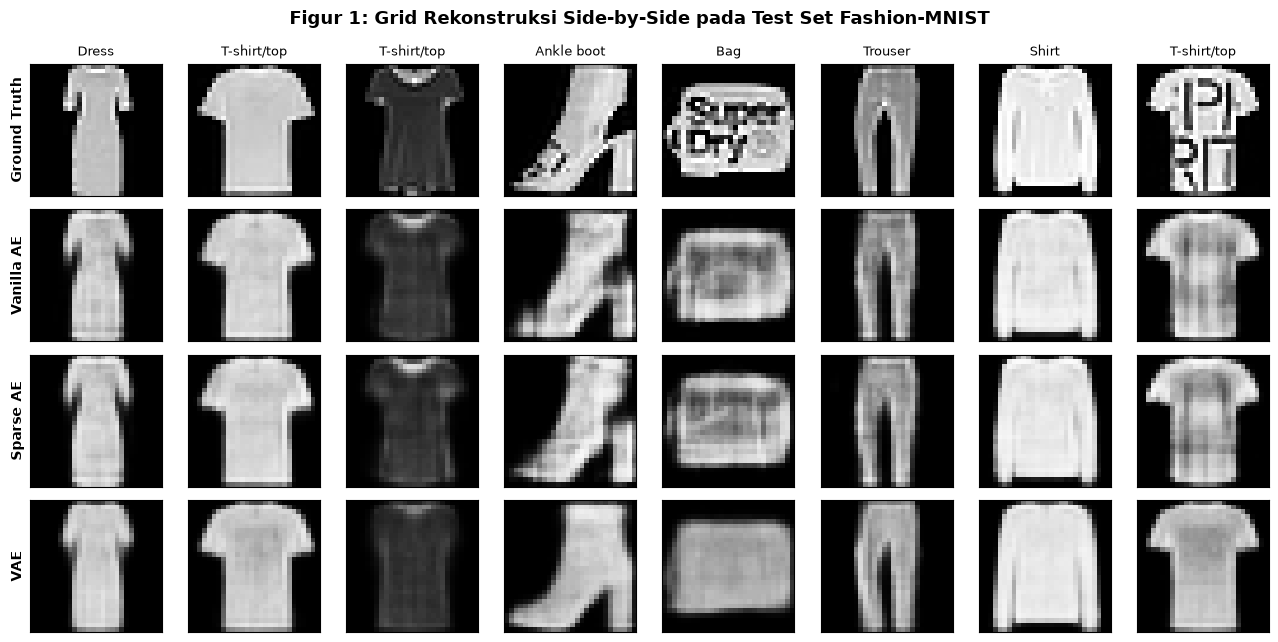

In [18]:
# === FIGUR 1: Grid Rekonstruksi Side-by-Side (8 sampel Test Set) ===
x_vis, y_vis = next(iter(te_dl))
x8 = x_vis[:8].to(dev)

with torch.no_grad():
    rec_ae = vanilla_ae(x8)[0].cpu()
    rec_sae = sparse_ae(x8)[0].cpu()
    rec_vae = vae(x8)[0].cpu()

rows = [
    ("Ground Truth", x8.cpu()),
    ("Vanilla AE", rec_ae),
    ("Sparse AE", rec_sae),
    ("VAE", rec_vae),
]

fig, axes = plt.subplots(4, 8, figsize=(13, 6.5))
for r_idx, (title, imgs) in enumerate(rows):
    for c_idx in range(8):
        ax = axes[r_idx, c_idx]
        ax.imshow(imgs[c_idx, 0], cmap="gray", vmin=0, vmax=1)
        ax.set_xticks([]); ax.set_yticks([])
        if r_idx == 0:
            ax.set_title(FASHION_LABELS[int(y_vis[c_idx])], fontsize=9)
        if c_idx == 0:
            ax.set_ylabel(title, fontsize=10, fontweight="bold")

plt.suptitle("Figur 1: Grid Rekonstruksi Side-by-Side pada Test Set Fashion-MNIST", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("figures/figur1_rekonstruksi.png", dpi=300, bbox_inches="tight")
plt.show()


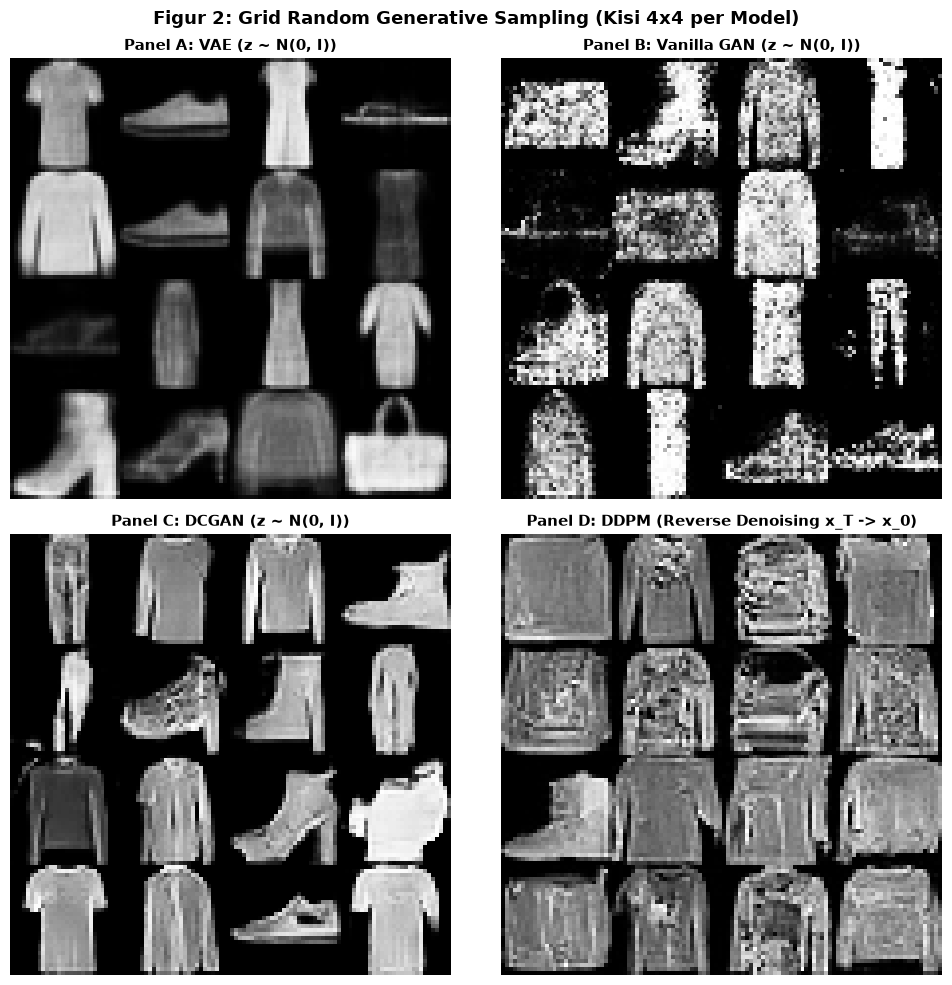

In [19]:
# === FIGUR 2: Grid Random Generative Sampling (4x4 = 16 sampel per model) ===
set_seed(SEED)
with torch.no_grad():
    samp_vae = vae.sample(16, dev).cpu()
    samp_vgan = vgan_G.sample_01(16, dev).cpu()
    samp_dcgan = dcgan_G.sample_01(16, dev).cpu()
    samp_ddpm = ddpm.sample_01(16, dev).cpu()

def make_4x4_grid(imgs):
    grid = np.zeros((4 * 28, 4 * 28), dtype=np.float32)
    for i in range(16):
        r, c = divmod(i, 4)
        grid[r*28:(r+1)*28, c*28:(c+1)*28] = imgs[i, 0].numpy()
    return grid

panels = [
    ("Panel A: VAE (z ~ N(0, I))", samp_vae),
    ("Panel B: Vanilla GAN (z ~ N(0, I))", samp_vgan),
    ("Panel C: DCGAN (z ~ N(0, I))", samp_dcgan),
    ("Panel D: DDPM (Reverse Denoising x_T -> x_0)", samp_ddpm),
]

fig, axes = plt.subplots(2, 2, figsize=(10, 10))
for ax, (title, imgs) in zip(axes.flat, panels):
    ax.imshow(make_4x4_grid(imgs), cmap="gray", vmin=0, vmax=1)
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.axis("off")

plt.suptitle("Figur 2: Grid Random Generative Sampling (Kisi 4x4 per Model)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("figures/figur2_random_sampling.png", dpi=300, bbox_inches="tight")
plt.show()


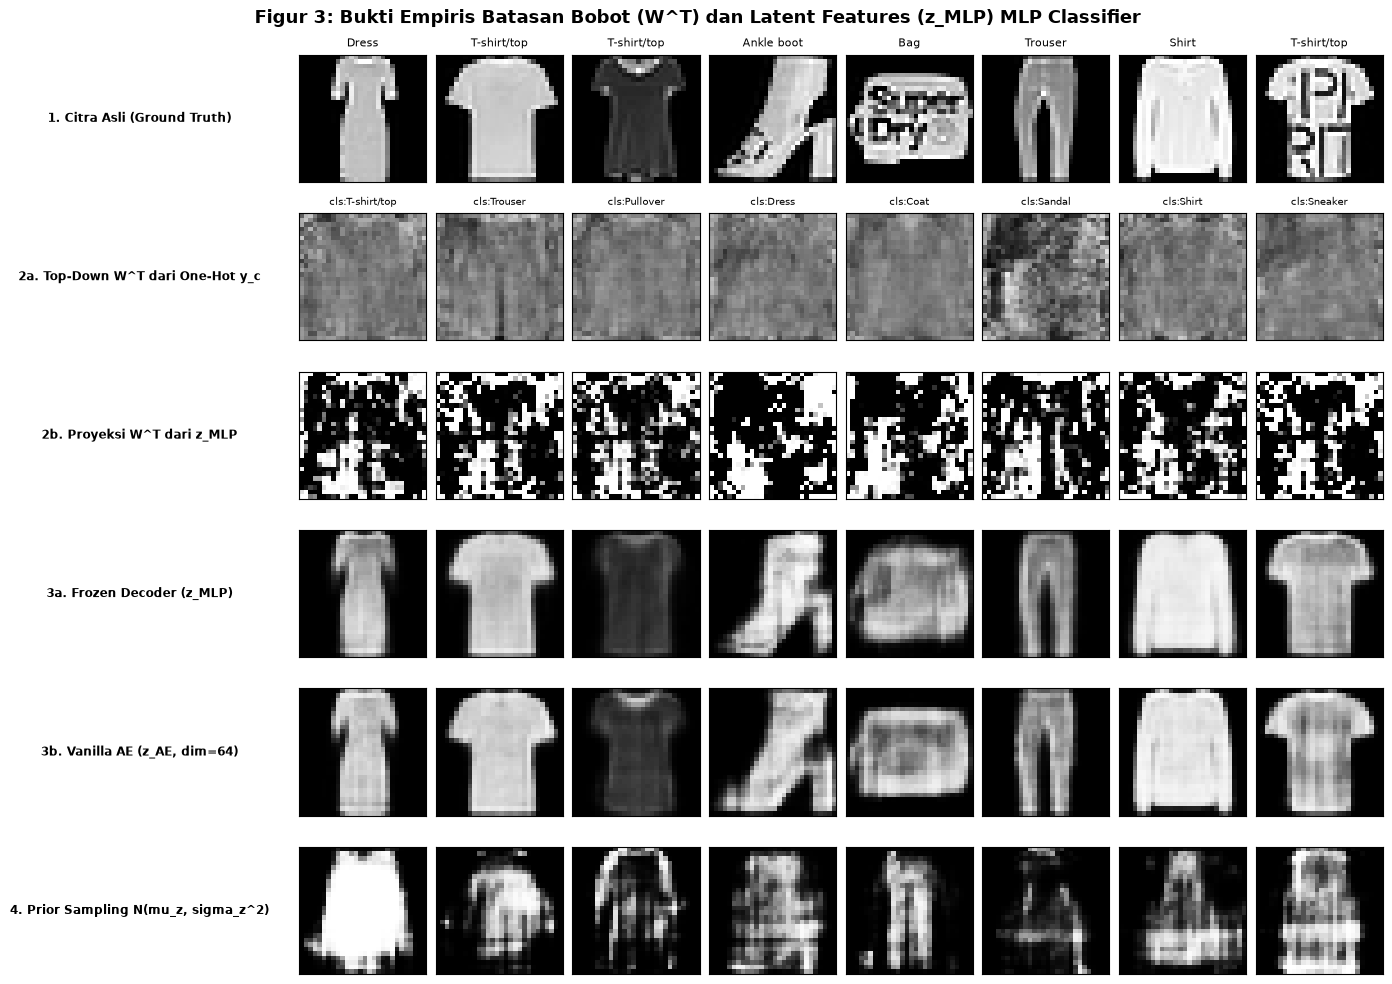

In [20]:
# === FIGUR 3: Bukti Empiris Batasan Bobot & Latent Features MLP Classifier (4 Panel) ===
with torch.no_grad():
    x_gt = x8.cpu()
    td_cls = topdown_from_class()[:8].cpu()
    proj_lat = project_from_latent(x8).cpu()
    rec_mlp_frozen = frozen_dec(mlp_clf.features(x8)).cpu()
    rec_ae_comp = vanilla_ae(x8)[0].cpu()
    prior_mlp = mlp_prior_samples[:8].cpu()

panel_rows = [
    ("1. Citra Asli (Ground Truth)", x_gt),
    ("2a. Top-Down W^T dari One-Hot y_c", td_cls),
    ("2b. Proyeksi W^T dari z_MLP", proj_lat),
    ("3a. Frozen Decoder (z_MLP)", rec_mlp_frozen),
    ("3b. Vanilla AE (z_AE, dim=64)", rec_ae_comp),
    ("4. Prior Sampling N(mu_z, sigma_z^2)", prior_mlp),
]

fig, axes = plt.subplots(len(panel_rows), 8, figsize=(14, 10))
for r_idx, (label, imgs) in enumerate(panel_rows):
    for c_idx in range(8):
        ax = axes[r_idx, c_idx]
        ax.imshow(imgs[c_idx, 0], cmap="gray", vmin=0, vmax=1)
        ax.set_xticks([]); ax.set_yticks([])
        if r_idx == 0:
            ax.set_title(FASHION_LABELS[int(y_vis[c_idx])], fontsize=8)
        elif r_idx == 1:
            ax.set_title(f"cls:{FASHION_LABELS[c_idx]}", fontsize=7)
        if c_idx == 0:
            ax.set_ylabel(label, fontsize=8.5, fontweight="bold", rotation=0, labelpad=115, va="center")

plt.suptitle("Figur 3: Bukti Empiris Batasan Bobot (W^T) dan Latent Features (z_MLP) MLP Classifier", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("figures/figur3_mlp_limitations.png", dpi=300, bbox_inches="tight")
plt.show()


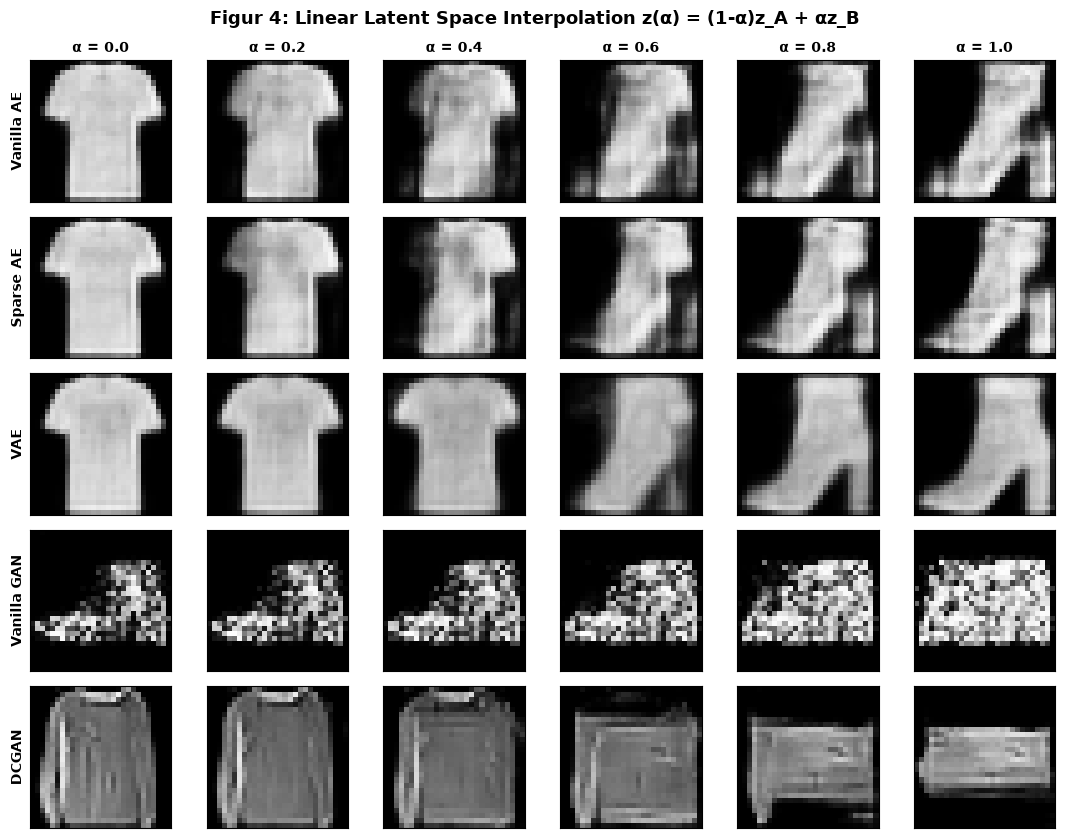

In [21]:
img_A, img_B = None, None
for x_b, y_b in te_dl:
    for i in range(len(y_b)):
        if int(y_b[i]) == 0 and img_A is None:
            img_A = x_b[i:i+1].to(dev)
        elif int(y_b[i]) == 9 and img_B is None:
            img_B = x_b[i:i+1].to(dev)
        if img_A is not None and img_B is not None:
            break
    if img_A is not None and img_B is not None:
        break

alphas = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]

def interpolate_and_decode(zA, zB, decode_fn):
    zs = torch.cat([(1 - a) * zA + a * zB for a in alphas], dim=0)
    return decode_fn(zs).cpu()

set_seed(SEED)
with torch.no_grad():
    interp_ae = interpolate_and_decode(vanilla_ae.encode(img_A), vanilla_ae.encode(img_B), vanilla_ae.decode)
    interp_sae = interpolate_and_decode(sparse_ae.encode(img_A), sparse_ae.encode(img_B), sparse_ae.decode)
    muA, _ = vae.encode(img_A); muB, _ = vae.encode(img_B)
    interp_vae = interpolate_and_decode(muA, muB, vae.decode)

    # Untuk GAN (tanpa encoder), interpolasi dilakukan antara dua titik acak kontras z_A, z_B ~ N(0, I)
    zA_gan = torch.randn(1, GAN_LATENT_DIM, device=dev)
    zB_gan = torch.randn(1, GAN_LATENT_DIM, device=dev)
    interp_vgan = interpolate_and_decode(zA_gan, zB_gan, lambda z: (vgan_G(z) + 1.0) / 2.0)
    interp_dcgan = interpolate_and_decode(zA_gan, zB_gan, lambda z: (dcgan_G(z) + 1.0) / 2.0)

interp_rows = [
    ("Vanilla AE", interp_ae),
    ("Sparse AE", interp_sae),
    ("VAE", interp_vae),
    ("Vanilla GAN", interp_vgan),
    ("DCGAN", interp_dcgan),
]

fig, axes = plt.subplots(len(interp_rows), len(alphas), figsize=(11, 8.5))
for r_idx, (name, imgs) in enumerate(interp_rows):
    for c_idx, a in enumerate(alphas):
        ax = axes[r_idx, c_idx]
        ax.imshow(imgs[c_idx, 0], cmap="gray", vmin=0, vmax=1)
        ax.set_xticks([]); ax.set_yticks([])
        if r_idx == 0:
            ax.set_title(f"α = {a:.1f}", fontsize=10, fontweight="bold")
        if c_idx == 0:
            ax.set_ylabel(name, fontsize=10, fontweight="bold")

plt.suptitle("Figur 4: Linear Latent Space Interpolation z(α) = (1-α)z_A + αz_B", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("figures/figur4_latent_interpolation.png", dpi=300, bbox_inches="tight")
plt.show()


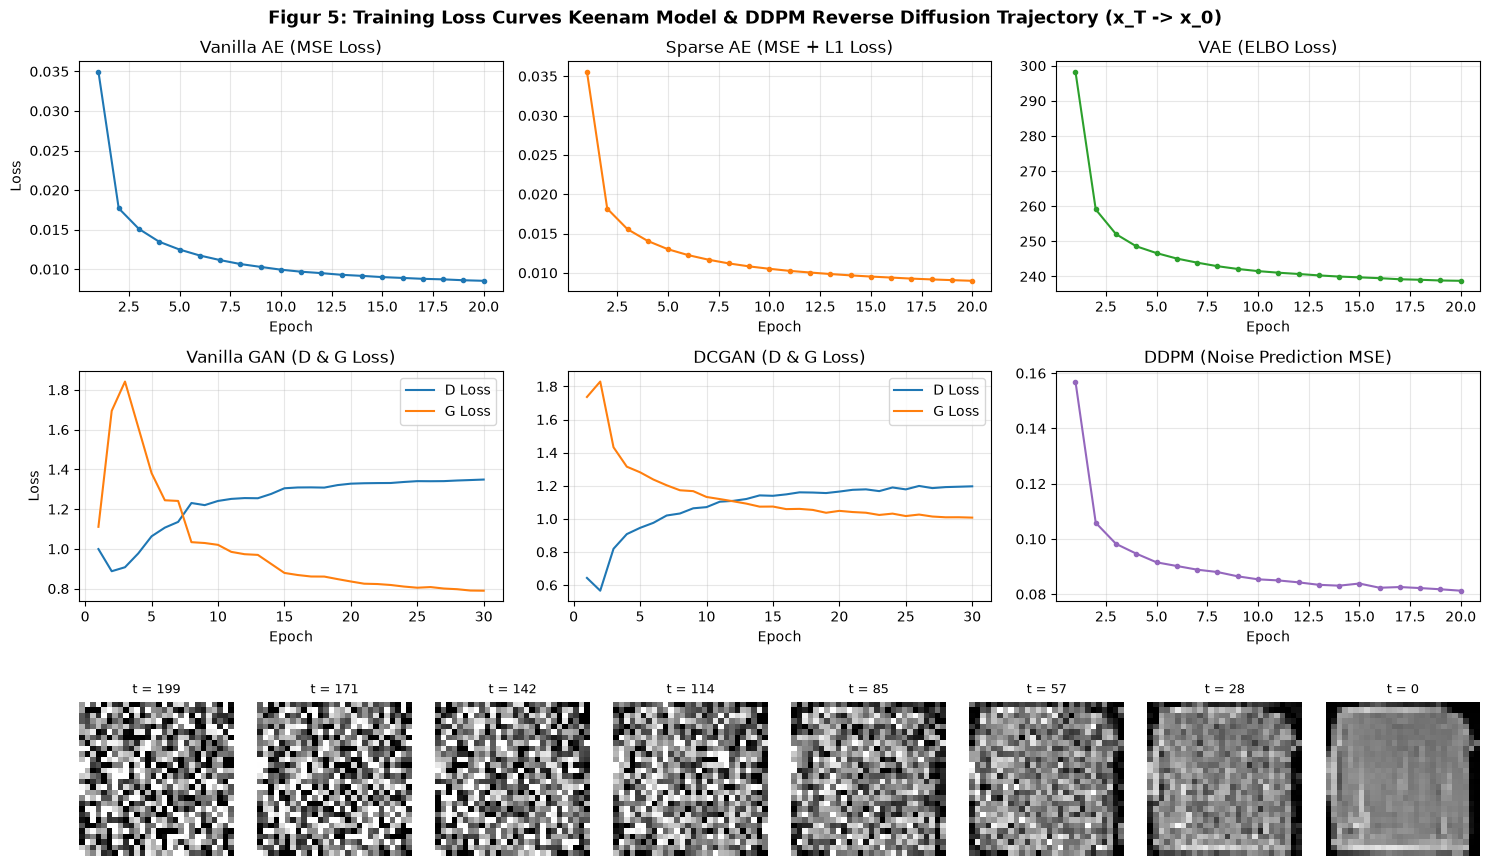

In [22]:
# === FIGUR 5: Training Loss Curves (6 Model) & DDPM Reverse Denoising Trajectory ===
fig = plt.figure(figsize=(15, 9))
gs = fig.add_gridspec(3, 3, height_ratios=[1, 1, 0.85])

# Baris 1: Vanilla AE, Sparse AE, VAE
ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(range(1, len(histories["Vanilla AE"]) + 1), histories["Vanilla AE"], marker="o", ms=3)
ax1.set_title("Vanilla AE (MSE Loss)"); ax1.set_xlabel("Epoch"); ax1.set_ylabel("Loss"); ax1.grid(alpha=0.3)

ax2 = fig.add_subplot(gs[0, 1])
ax2.plot(range(1, len(histories["Sparse AE"]) + 1), histories["Sparse AE"], marker="o", ms=3, color="tab:orange")
ax2.set_title("Sparse AE (MSE + L1 Loss)"); ax2.set_xlabel("Epoch"); ax2.grid(alpha=0.3)

ax3 = fig.add_subplot(gs[0, 2])
ax3.plot(range(1, len(histories["VAE"]) + 1), histories["VAE"], marker="o", ms=3, color="tab:green")
ax3.set_title("VAE (ELBO Loss)"); ax3.set_xlabel("Epoch"); ax3.grid(alpha=0.3)

# Baris 2: Vanilla GAN, DCGAN, DDPM
ax4 = fig.add_subplot(gs[1, 0])
ax4.plot(range(1, len(histories["Vanilla GAN"]["D"]) + 1), histories["Vanilla GAN"]["D"], label="D Loss")
ax4.plot(range(1, len(histories["Vanilla GAN"]["G"]) + 1), histories["Vanilla GAN"]["G"], label="G Loss")
ax4.set_title("Vanilla GAN (D & G Loss)"); ax4.set_xlabel("Epoch"); ax4.set_ylabel("Loss"); ax4.legend(); ax4.grid(alpha=0.3)

ax5 = fig.add_subplot(gs[1, 1])
ax5.plot(range(1, len(histories["DCGAN"]["D"]) + 1), histories["DCGAN"]["D"], label="D Loss")
ax5.plot(range(1, len(histories["DCGAN"]["G"]) + 1), histories["DCGAN"]["G"], label="G Loss")
ax5.set_title("DCGAN (D & G Loss)"); ax5.set_xlabel("Epoch"); ax5.legend(); ax5.grid(alpha=0.3)

ax6 = fig.add_subplot(gs[1, 2])
ax6.plot(range(1, len(histories["DDPM"]) + 1), histories["DDPM"], marker="o", ms=3, color="tab:purple")
ax6.set_title("DDPM (Noise Prediction MSE)"); ax6.set_xlabel("Epoch"); ax6.grid(alpha=0.3)

# Baris 3: DDPM Reverse Denoising Trajectory (x_T -> x_0)
set_seed(SEED)
_, traj = ddpm.sample_01(n=1, device=dev, return_trajectory=True, capture_steps=8)
sub_gs = gs[2, :].subgridspec(1, len(traj))
for idx, (step_t, img_t) in enumerate(traj):
    ax_t = fig.add_subplot(sub_gs[0, idx])
    ax_t.imshow(img_t[0, 0], cmap="gray", vmin=0, vmax=1)
    ax_t.set_title(f"t = {step_t}", fontsize=9)
    ax_t.axis("off")

plt.suptitle("Figur 5: Training Loss Curves Keenam Model & DDPM Reverse Diffusion Trajectory (x_T -> x_0)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("figures/figur5_loss_dan_ddpm_trajectory.png", dpi=300, bbox_inches="tight")
plt.show()
